## Exploratory Data Analysis

In [44]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt


STATE_NAMES = ["Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado", "Connecticut", "Delaware", "Florida", "Georgia", "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa", "Kansas", "Kentucky", "Louisiana", "Maine", "Maryland", "Massachusetts", "Michigan", "Minnesota", "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire", "New Jersey", "New Mexico", "New York", "North Carolina", "North Dakota", "Ohio", "Oklahoma", "Oregon", "Pennsylvania", "Rhode Island", "South Carolina", "South Dakota", "Tennessee", "Texas", "Utah", "Vermont", "Virginia", "Washington", "West Virginia", "Wisconsin", "Wyoming"]

vacancyrate_df = pd.read_csv("../data/processed/processedvacancyrate.csv")
vacancyrate_df.head()

,Year,Alabama,Alaska,Arizona,Arkansas,California,Colorado,Connecticut,Delaware,District of Columbia,...,South Dakota,Tennessee,Texas,Utah,Vermont,Virginia,Washington,West Virginia,Wisconsin,Wyoming
0,2005,16.2,19.7,17.1,14.6,8.6,12.5,8.8,17.5,12.8,...,12.8,11.7,13.2,9.2,20.6,11.0,8.4,17.9,13.9,13.2
1,2006,17.1,20.1,18.2,14.9,9.4,12.3,9.8,19.5,13.7,...,12.5,11.4,13.1,11.2,19.7,11.6,8.6,18.2,13.6,13.8
2,2007,18.5,22.5,19.1,15.2,10.1,13.0,9.6,21.3,13.8,...,12.1,11.6,13.8,11.6,20.3,12.6,8.1,17.8,14.1,14.0
3,2008,19.8,24.9,20.9,15.5,10.8,12.9,9.9,20.5,14.0,...,11.7,13.7,12.9,11.1,21.3,12.7,8.8,19.0,16.1,15.2
4,2009,17.5,24.9,22.4,15.7,11.3,13.3,9.8,20.2,15.7,...,11.3,13.4,12.9,11.9,21.7,12.2,10.2,19.4,16.4,15.7


### Minimum Wage

In [45]:
minwage_df = pd.read_csv("../data/processed/processedminwage.csv")
minwage_df.head()

,Year,Alabama,Alaska,Arkansas,Arizona,California,Colorado,Connecticut,District of Columbia,Delaware,...,South Dakota,Tennessee,Texas,Utah,Virginia,Vermont,Washington,Wisconsin,West Virginia,Wyoming
0,2005,5.15,7.15,5.15,5.15,6.75,5.15,7.10,6.60,6.15,...,5.15,5.15,5.15,5.15,5.15,7.00,7.35,5.15,5.15,5.15
1,2006,5.15,7.15,5.15,5.15,6.75,5.15,7.40,7.00,6.15,...,5.15,5.15,5.15,5.15,5.15,7.25,7.63,5.70,5.15,5.15
2,2007,5.15,7.15,6.25,6.75,7.50,6.85,7.65,7.00,6.65,...,5.15,5.15,5.15,5.15,5.15,7.53,7.93,6.50,5.85,5.15
3,2008,5.85,7.15,6.25,6.90,8.00,7.02,7.65,7.00,7.15,...,5.85,5.85,5.85,5.85,5.85,7.68,8.07,6.50,6.55,5.15
4,2009,6.55,7.15,6.25,7.25,8.00,7.28,8.00,7.55,7.15,...,6.55,6.55,6.55,6.55,6.55,8.06,8.55,6.50,7.25,5.15


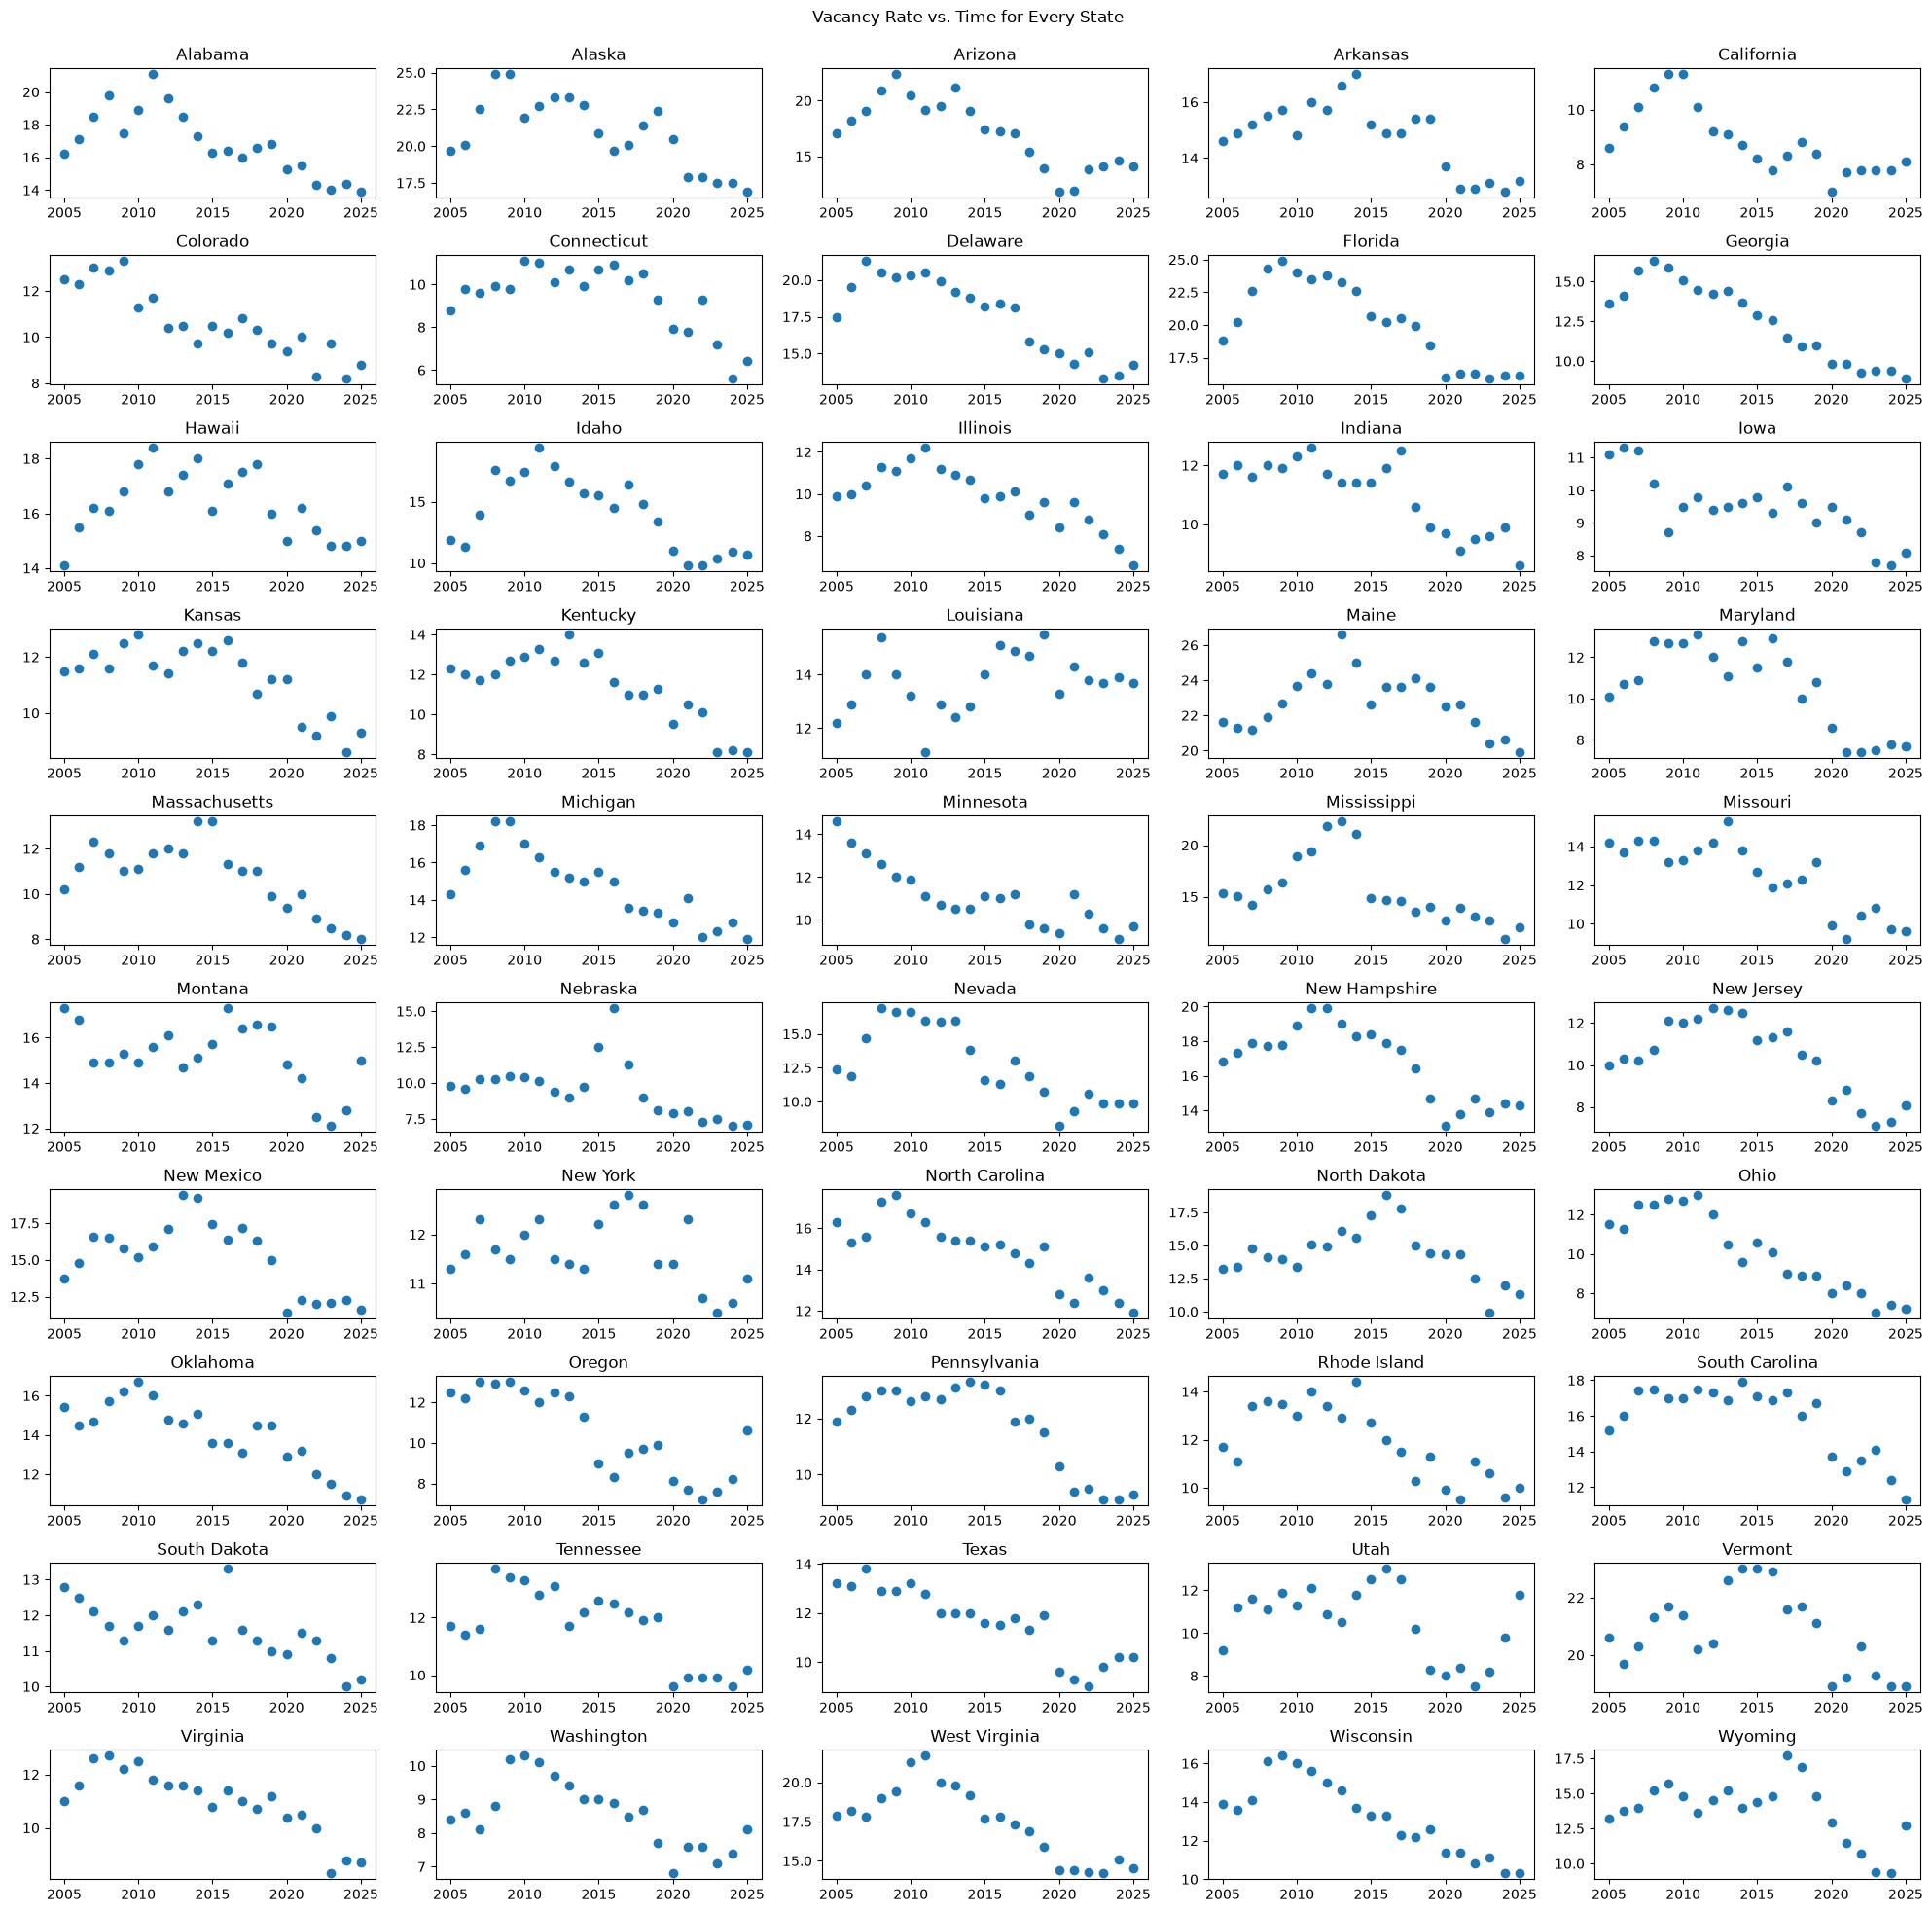

In [54]:
# plot vacancy rate w.r.t. time
fig, ax = plt.subplots(10, 5, figsize=(20,20))

for i, (ax, state) in enumerate(zip(ax.flat, STATE_NAMES)):
    x = vacancyrate_df["Year"]
    y = vacancyrate_df[state]
    # m, b = np.polyfit(x, y, 1)
    # ax.plot(x, m*x + b, color='red')
    ax.scatter(x, y)
    ax.set_title(f"{state}")

plt.suptitle("Vacancy Rate vs. Time for Every State")
plt.tight_layout()
fig.subplots_adjust(top=0.95)
plt.show()

In [47]:
wage_vacancy_corr = {}

for state in STATE_NAMES:
    wage_vacancy_corr[state] = minwage_df[state].corr(vacancyrate_df[state])

wage_vacancy_corr = pd.DataFrame.from_dict(wage_vacancy_corr, orient='index')
print(wage_vacancy_corr)

                       0
Alabama        -0.227846
Alaska         -0.785104
Arizona        -0.782051
Arkansas       -0.800931
California     -0.659834
Colorado       -0.829756
Connecticut    -0.802939
Delaware       -0.810027
Florida        -0.693413
Georgia        -0.842104
Hawaii         -0.446608
Idaho           0.083918
Illinois       -0.791137
Indiana        -0.351844
Iowa           -0.729222
Kansas         -0.284263
Kentucky       -0.212940
Louisiana       0.095148
Maine          -0.477692
Maryland       -0.786307
Massachusetts  -0.827826
Michigan       -0.708642
Minnesota      -0.769172
Mississippi     0.074403
Missouri       -0.843480
Montana        -0.579382
Nebraska       -0.419848
Nevada         -0.531553
New Hampshire  -0.127683
New Jersey     -0.811988
New Mexico     -0.650652
New York       -0.456997
North Carolina -0.418259
North Dakota    0.133738
Ohio           -0.735422
Oklahoma       -0.347434
Oregon         -0.740428
Pennsylvania   -0.149643
Rhode Island   -0.764367


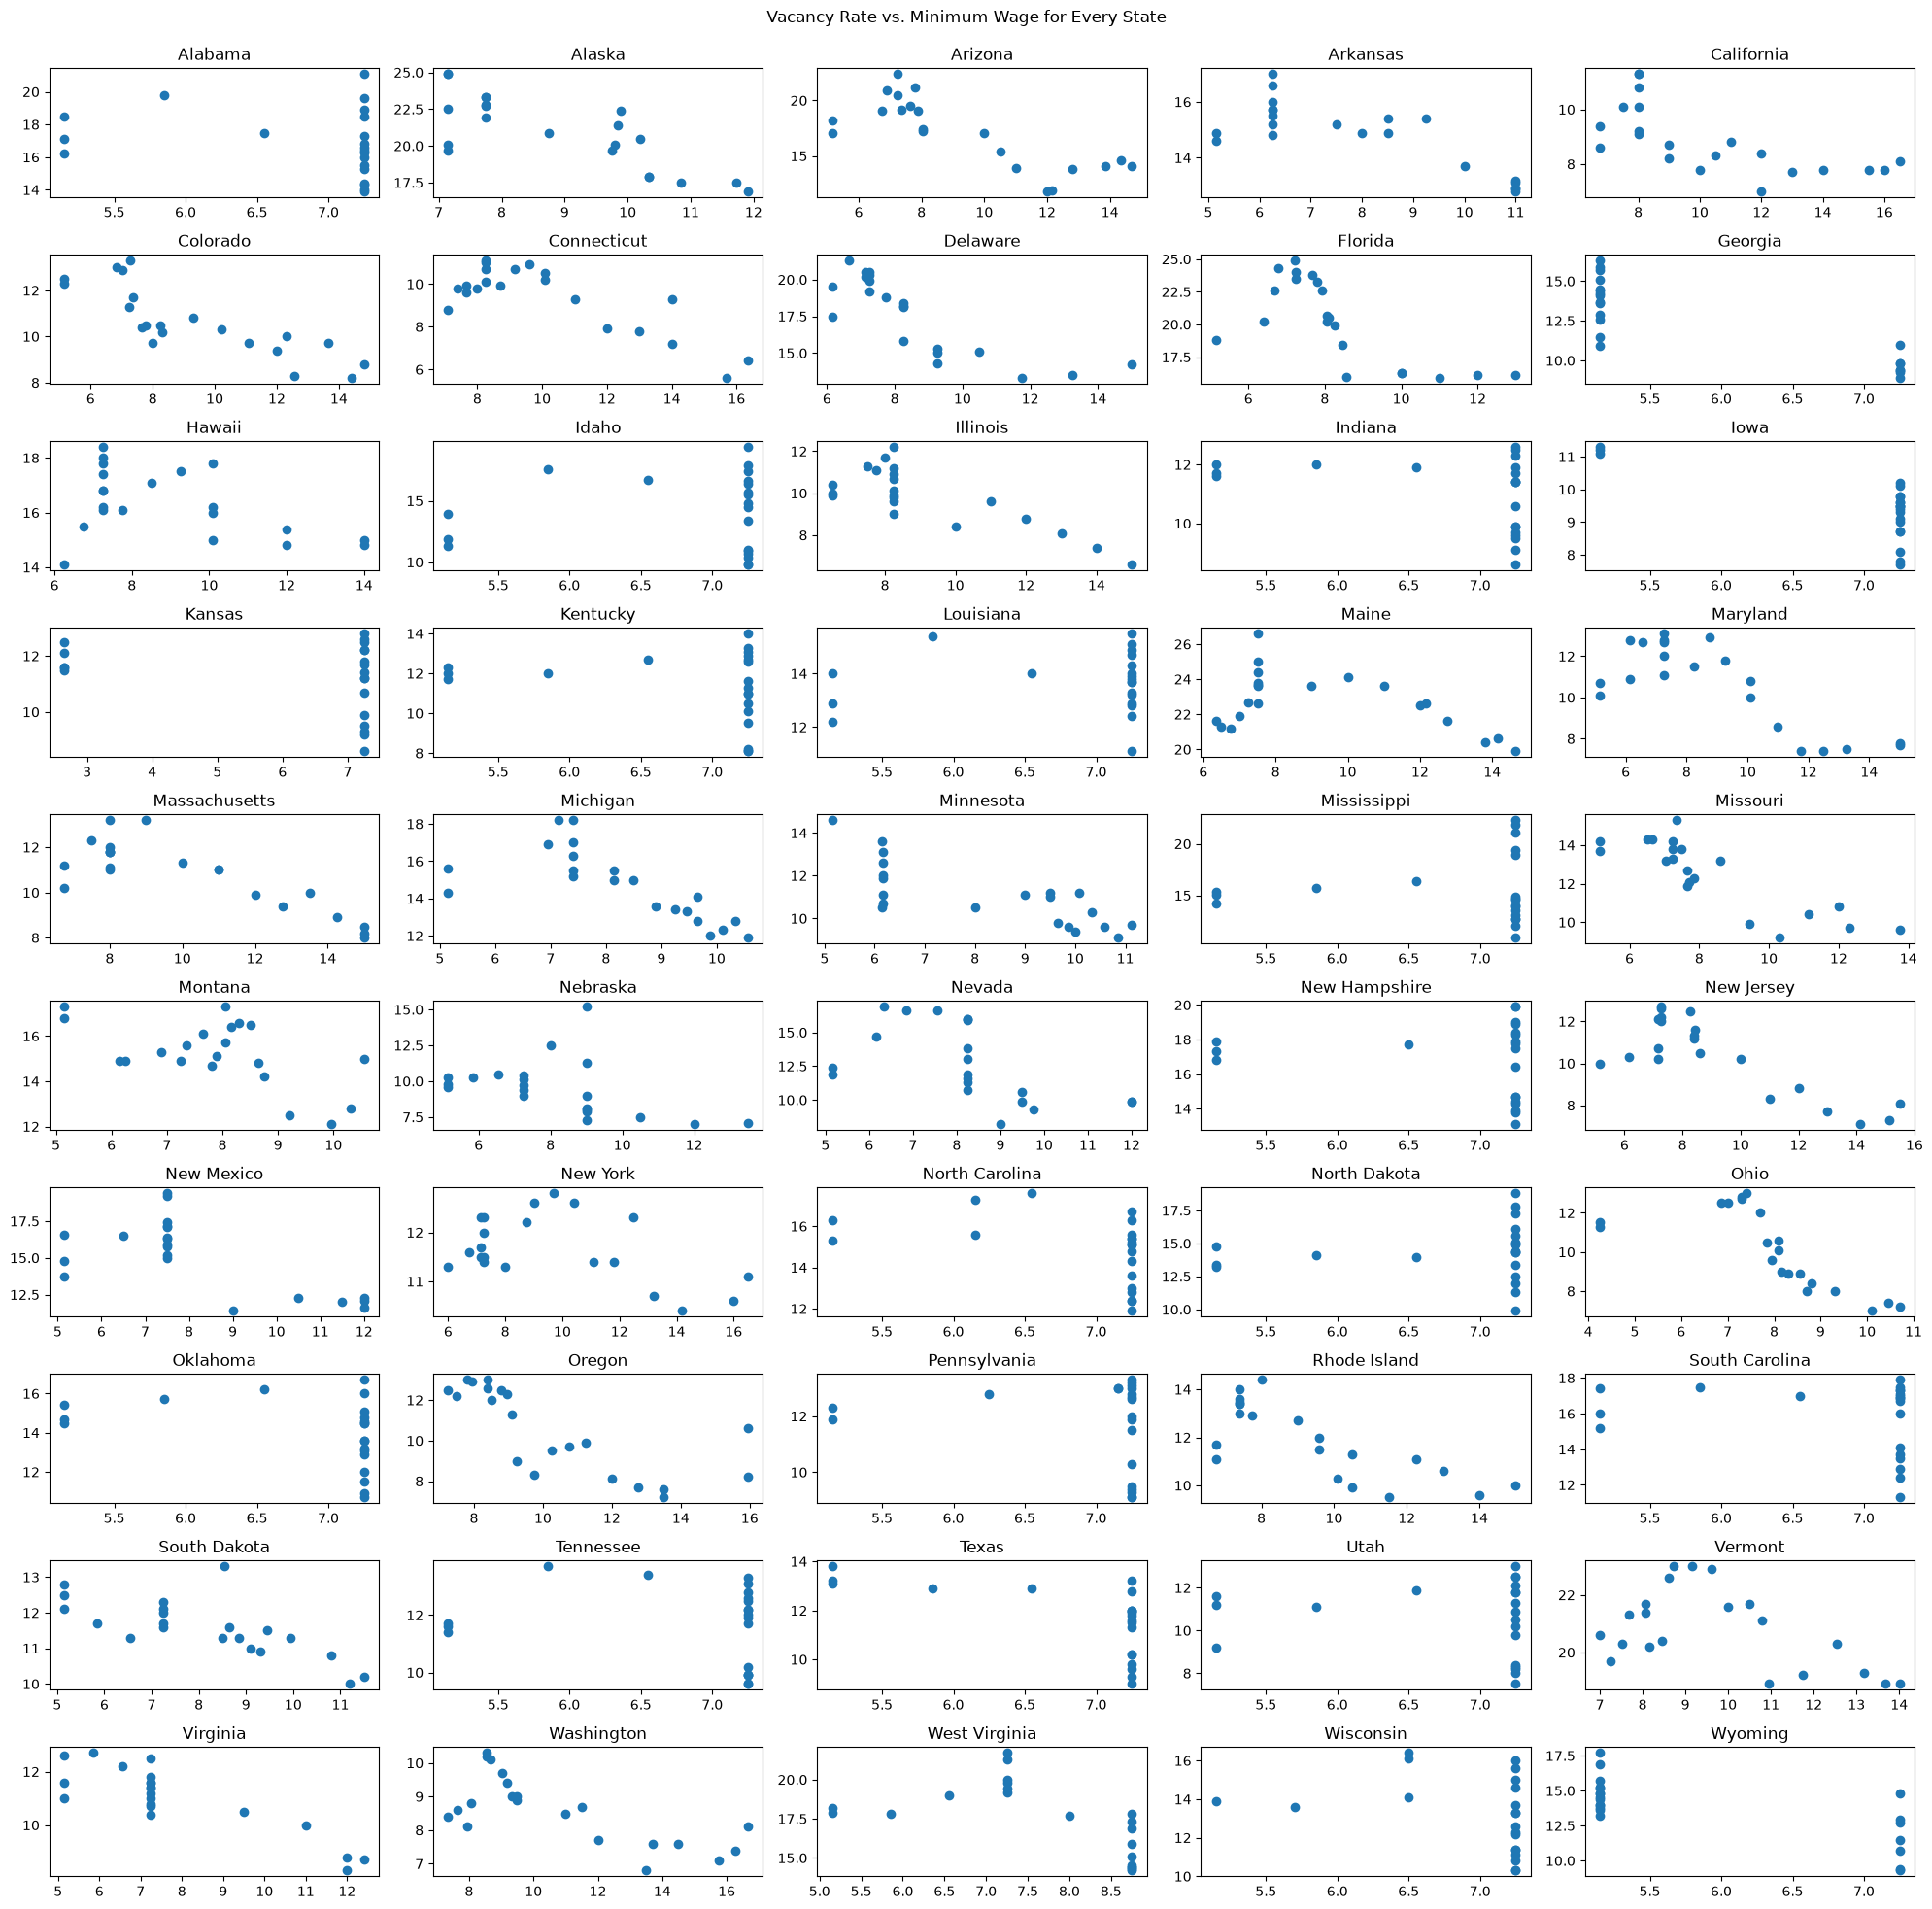

In [48]:
fig, ax = plt.subplots(10, 5, figsize=(20,20))

for i, (ax, state) in enumerate(zip(ax.flat, STATE_NAMES)):
    ax.scatter(minwage_df[state], vacancyrate_df[state])
    ax.set_title(f"{state}")

plt.suptitle("Vacancy Rate vs. Minimum Wage for Every State")
plt.tight_layout()
fig.subplots_adjust(top=0.95)
plt.show()

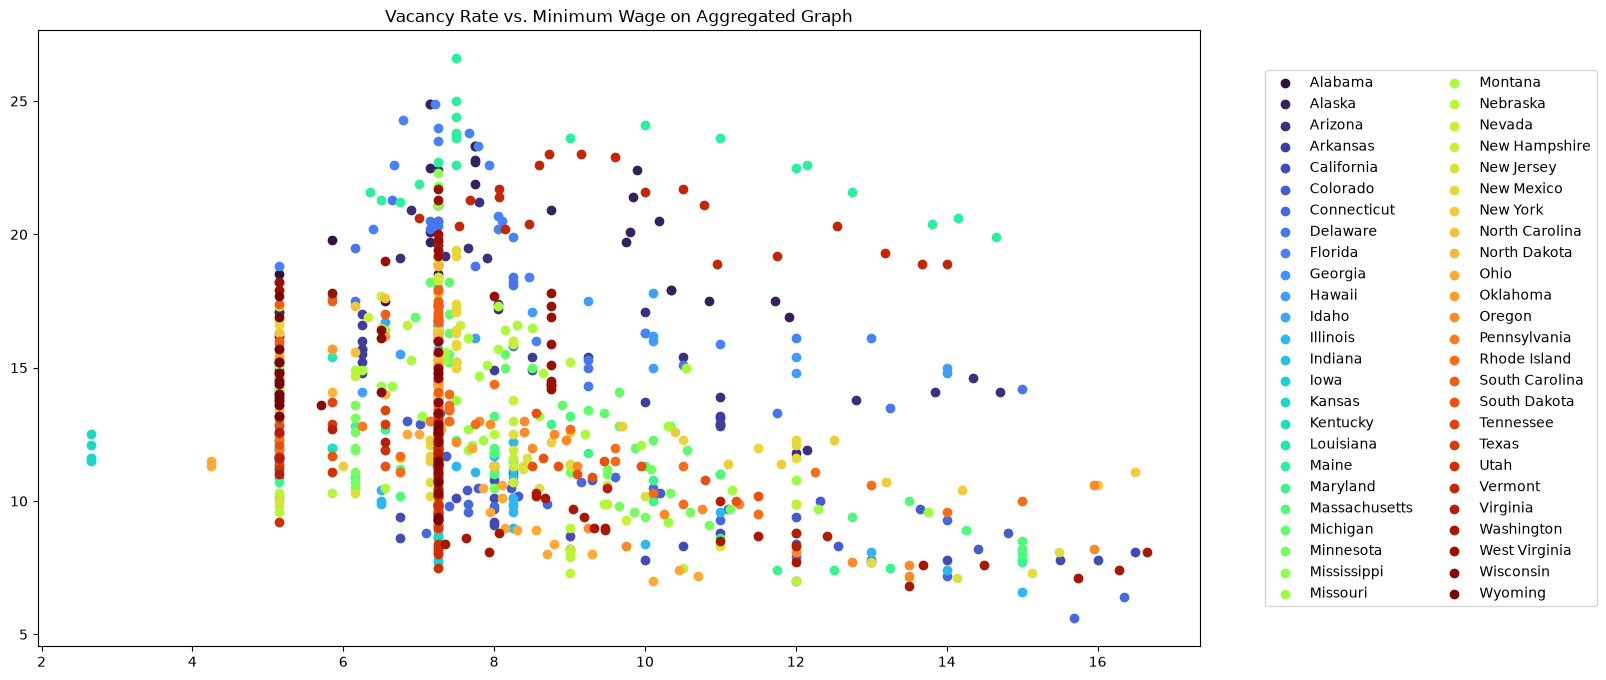

In [85]:
colors = plt.cm.turbo(np.linspace(0, 1, len(STATE_NAMES)))

plt.figure(figsize=(15, 8))
for i, state in enumerate(STATE_NAMES):
    x = minwage_df[state]
    y = vacancyrate_df[state]
    plt.scatter(x, y, color=colors[i], label=f"{state}")
plt.title("Vacancy Rate vs. Minimum Wage on Aggregated Graph")
plt.legend(loc="center left", bbox_to_anchor=(1.05, 0.5), ncol=2)
plt.show()

## Housing Price Index

In [49]:
hpi_df = pd.read_csv("../data/processed/state_hpi.csv")
hpi_df.head()

,Year,Alabama,Alaska,Arkansas,Arizona,California,Colorado,Connecticut,Delaware,Florida,...,South Dakota,Tennessee,Texas,Utah,Virginia,Vermont,Washington,Wisconsin,West Virginia,Wyoming
0,2005,341.58,367.78,346.51,581.47,1258.18,592.22,671.70,531.32,541.83,...,373.40,366.10,330.21,482.38,577.79,529.07,786.28,286.59,456.83,424.58
1,2006,368.55,404.50,367.01,685.54,1389.89,612.65,711.09,579.07,628.61,...,391.56,392.45,349.74,559.72,637.48,571.02,908.54,302.29,473.05,478.51
2,2007,383.71,418.31,376.16,677.37,1326.76,617.90,711.10,593.57,610.61,...,406.10,408.56,366.68,624.22,647.86,582.55,969.03,307.02,478.21,523.03
3,2008,387.01,416.81,374.50,595.18,1064.55,610.97,684.99,575.93,515.70,...,414.57,409.47,372.08,620.29,617.83,581.49,950.43,304.99,472.23,533.05
4,2009,378.09,411.24,367.14,484.84,902.73,601.15,635.49,537.73,424.21,...,414.39,399.59,370.63,567.05,576.32,562.32,858.85,295.35,454.10,519.45


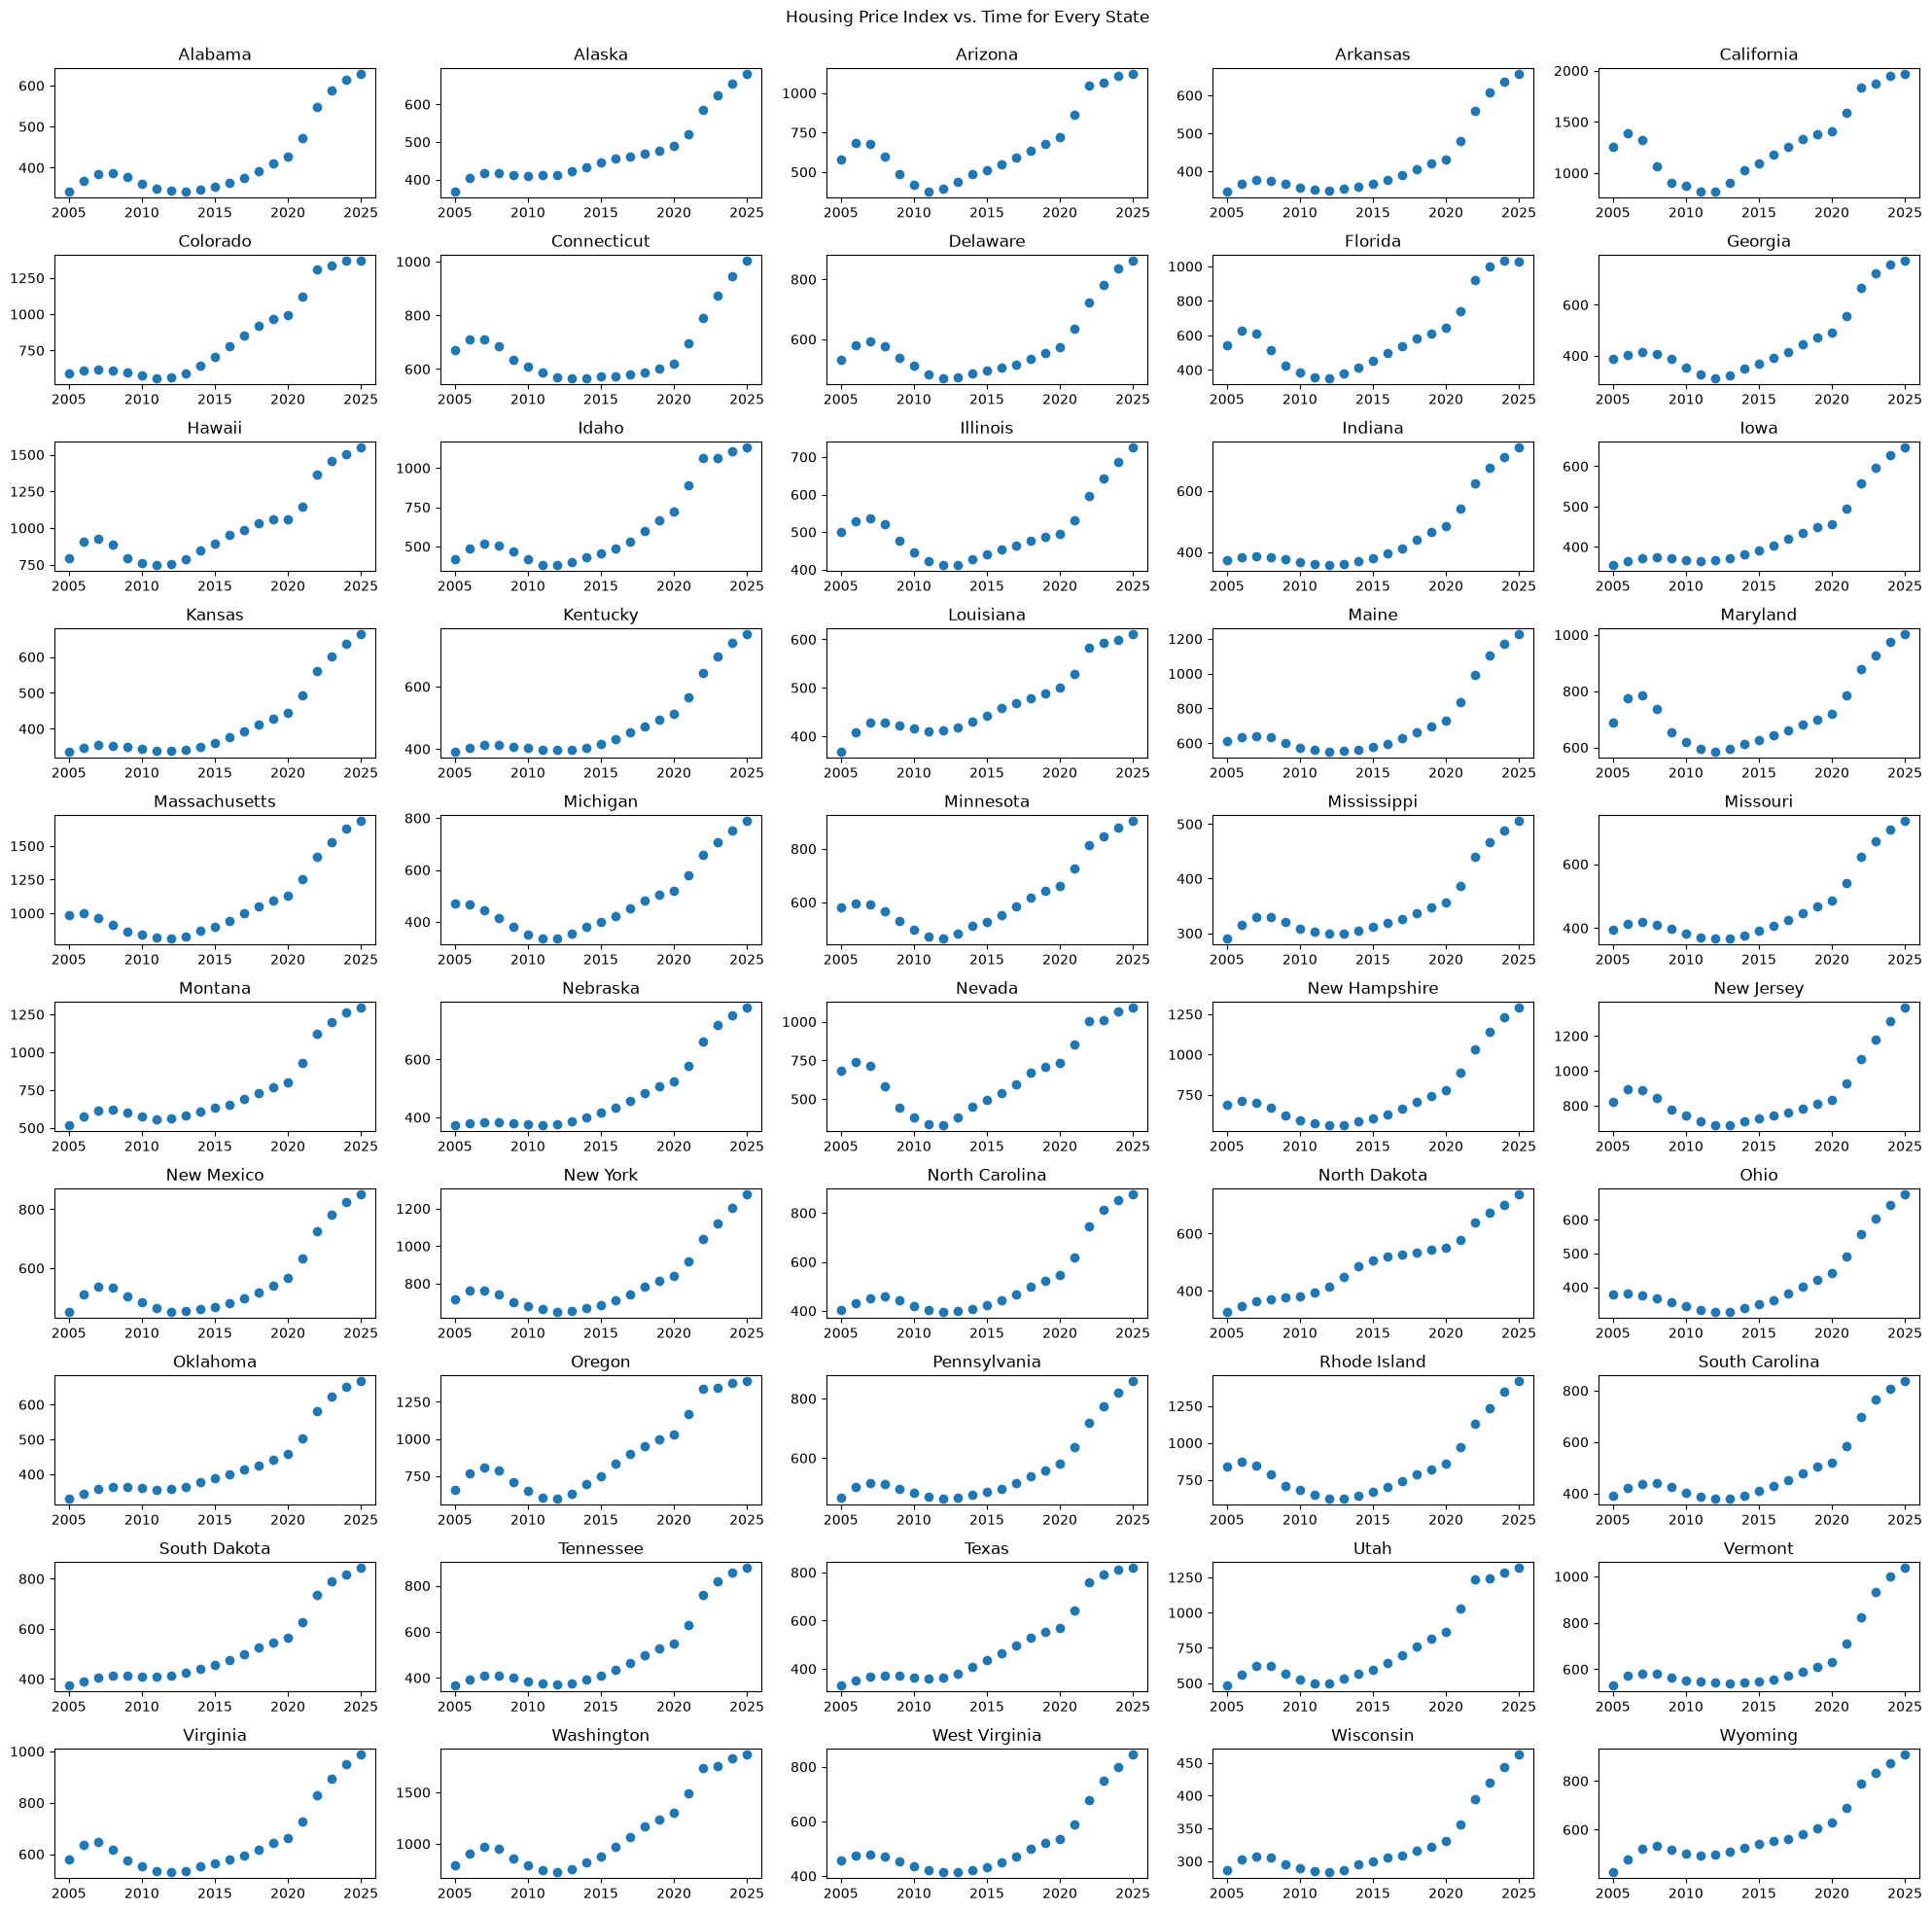

In [50]:
# plot HPI w.r.t. time
fig, ax = plt.subplots(10, 5, figsize=(20,20))

for i, (ax, state) in enumerate(zip(ax.flat, STATE_NAMES)):
    ax.scatter(hpi_df["Year"], hpi_df[state])
    ax.set_title(f"{state}")

plt.suptitle("Housing Price Index vs. Time for Every State")
plt.tight_layout()
fig.subplots_adjust(top=0.95)
plt.show()

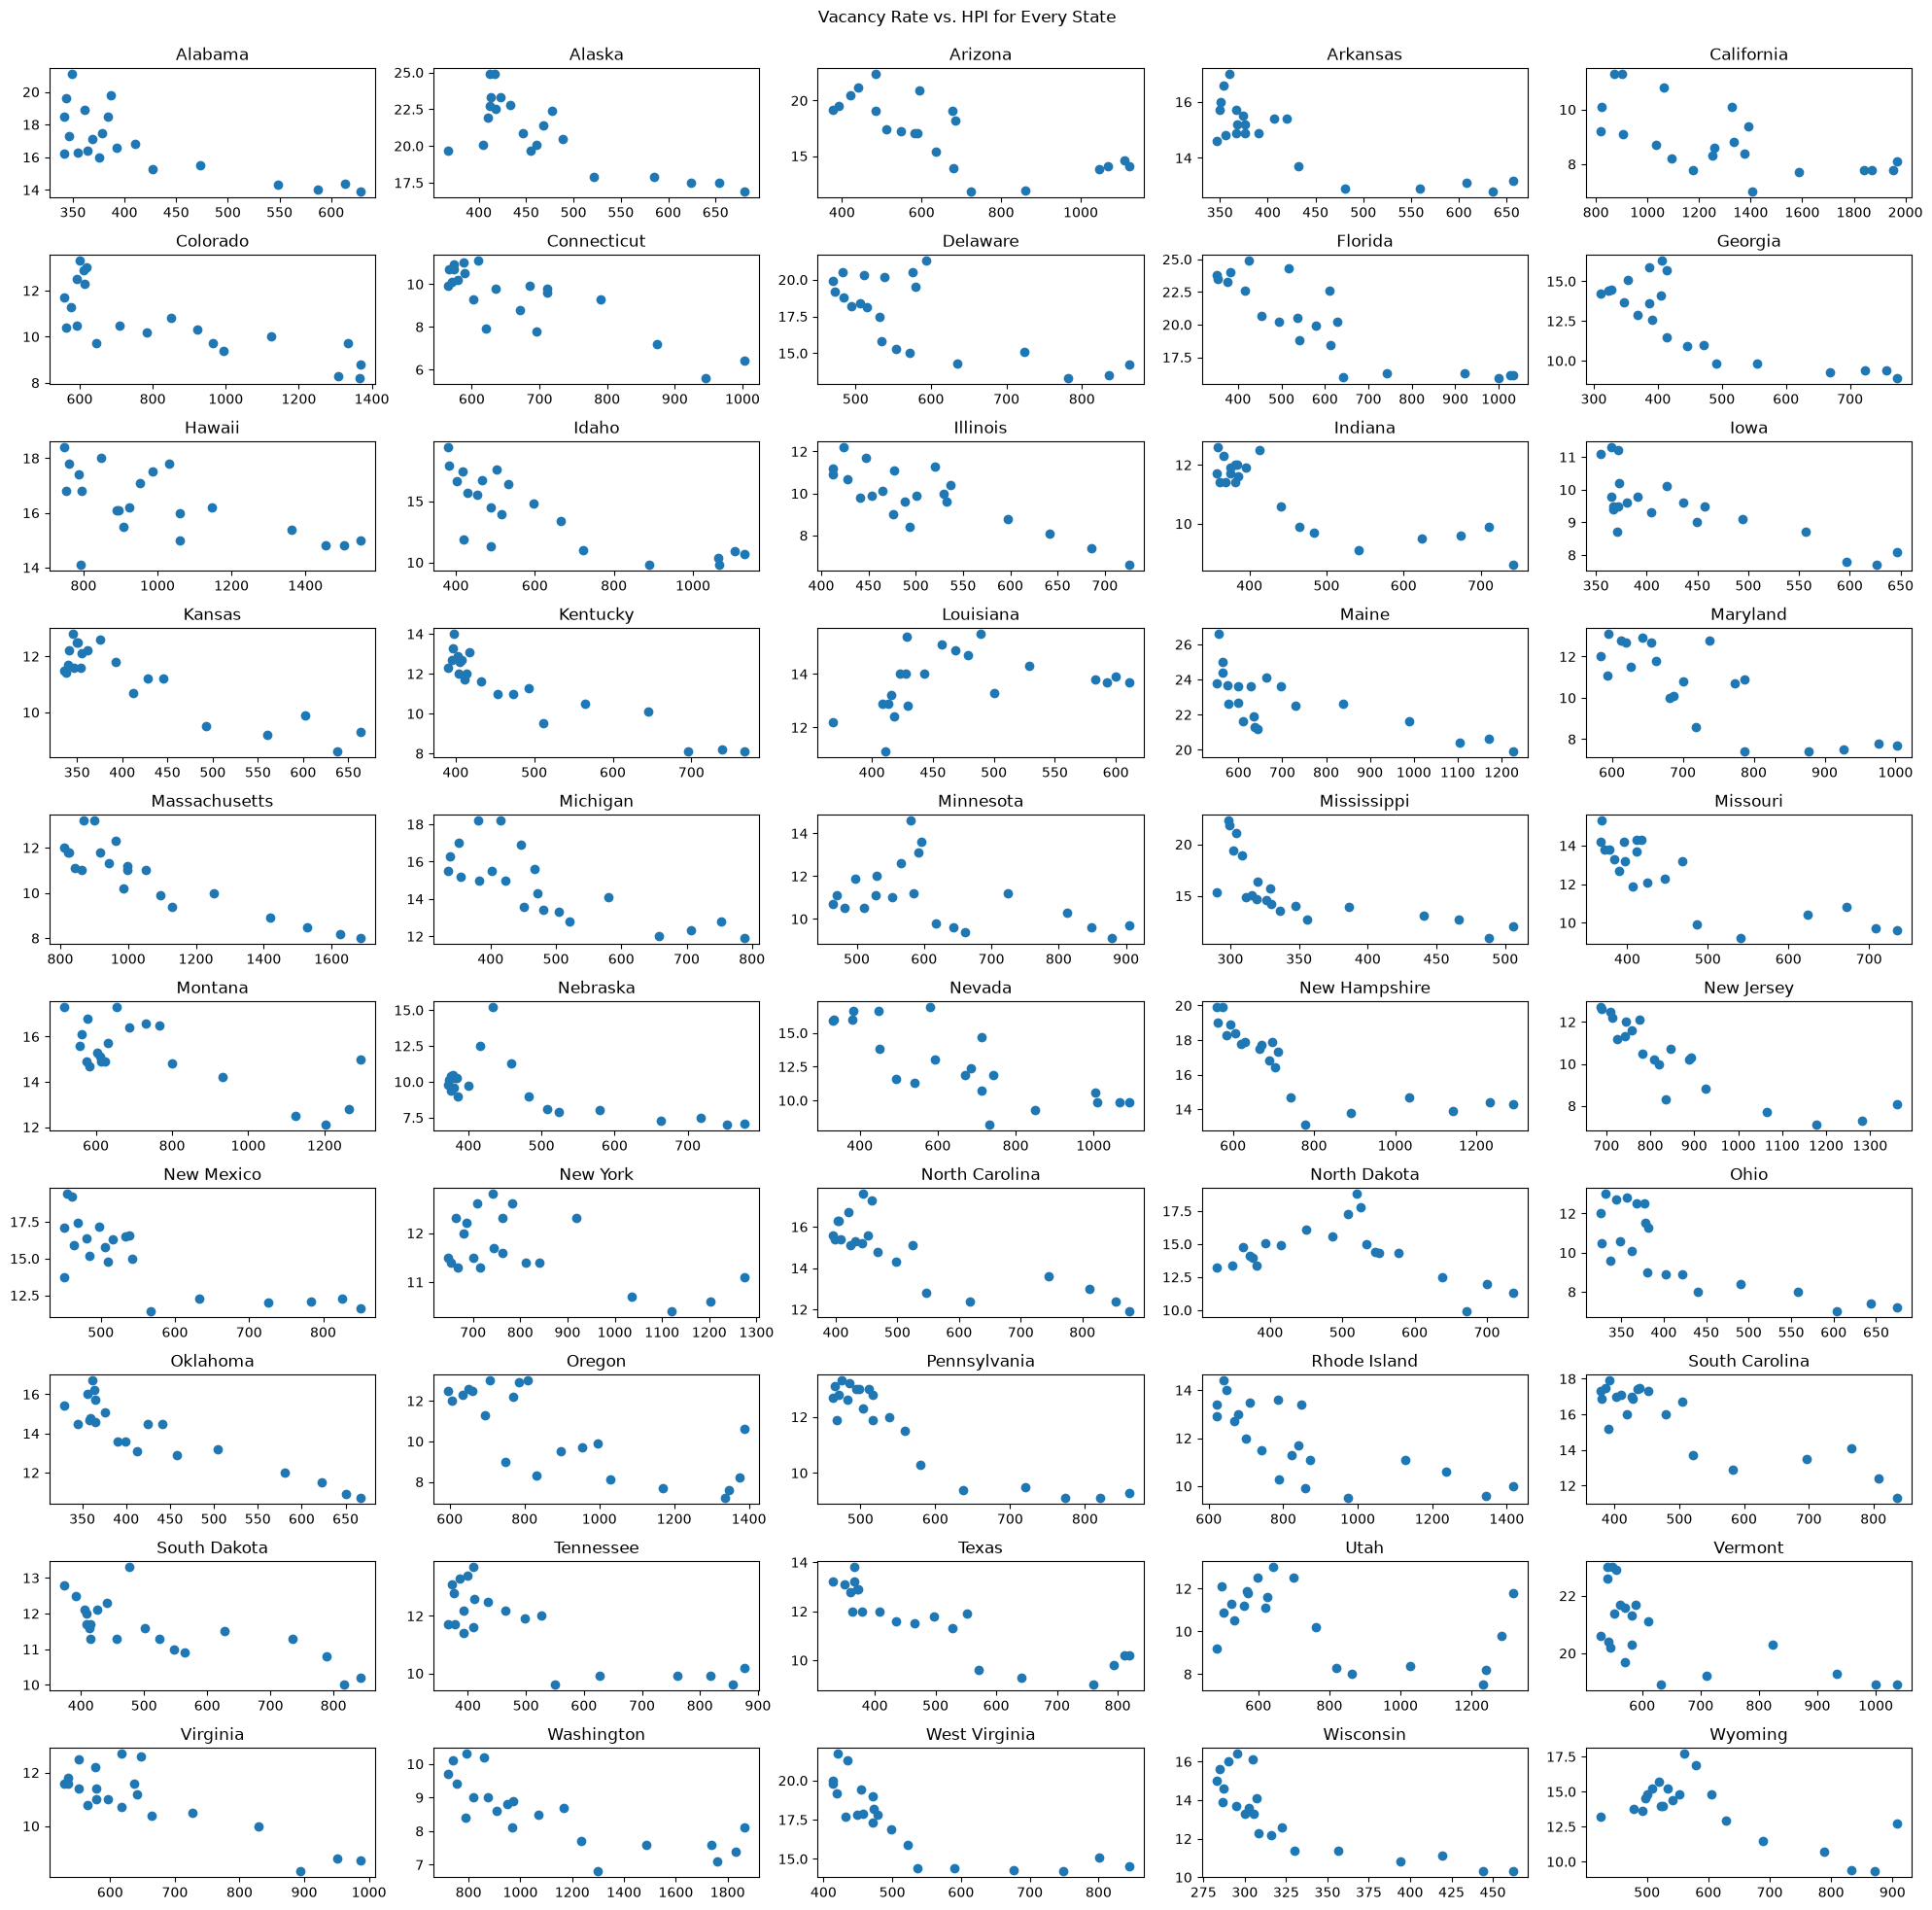

In [51]:
fig, ax = plt.subplots(10, 5, figsize=(20,20))

for i, (ax, state) in enumerate(zip(ax.flat, STATE_NAMES)):
    ax.scatter(hpi_df[state], vacancyrate_df[state])
    ax.set_title(f"{state}")

plt.suptitle("Vacancy Rate vs. HPI for Every State")
plt.tight_layout()
fig.subplots_adjust(top=0.95)
plt.show()